# Assignment 1 Report: Building and Evaluating Convolutional Neural Networks

This notebook presents the executed results of Tasks 1–6. The implementation is stored in the `src` package. This notebook is the final English report and visual presentation.

## Experimental scope

The experiment uses CIFAR-10 and compares a CIFAR-10 adapted AlexNet with a CIFAR-10 adapted ResNet. It also studies capacity, L2 regularisation, dropout, data augmentation, corruption robustness, prediction errors, FGSM adversarial sensitivity, and computational cost.

The training budget is fixed at 30 epochs per configuration. Every controlled comparison uses the same seed, data split, batch size, optimiser, learning-rate schedule, and checkpoint-selection rule.

## Measured results from the completed 30-epoch run

The tables below are copied from the regenerated files in `outputs/metrics/`.

| Configuration | Parameters | Test accuracy |
|---|---:|---:|
| AlexNet baseline | 6,976,842 | 0.8249 |
| ResNet baseline | 11,173,962 | 0.8350 |
| Small ResNet | 701,466 | 0.7888 |
| ResNet dropout 0.3 | 11,173,962 | 0.8325 |
| ResNet dropout 0.5 | 11,173,962 | 0.8170 |
| ResNet L2 | 11,173,962 | 0.8342 |
| ResNet augmented | 11,173,962 | 0.9037 |

Robustness results: the basic ResNet reached 0.8350 clean, 0.7789 under noise and 0.6632 under rotation. The augmented ResNet reached 0.9037 clean, 0.7349 under noise and 0.6824 under rotation. The measured FGSM example changed the prediction from class 3 (cat) to class 5 (dog) at normalized epsilon 0.05.


In [1]:
from pathlib import Path
import json
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
OUTPUT_ROOT = PROJECT_ROOT / "outputs"
metrics = OUTPUT_ROOT / "metrics"
model_results = pd.read_csv(metrics / "model_results.csv")
robustness_results = pd.read_csv(metrics / "robustness_results.csv")
adversarial = json.loads((metrics / "adversarial_result.json").read_text())
print(model_results.to_string(index=False))
print(robustness_results.to_string(index=False))
print(adversarial)

              name  parameters  training_seconds  best_validation_accuracy  test_loss  test_accuracy  inference_seconds  weight_decay
  AlexNet baseline     6976842        292.339574                    0.8300   0.910819         0.8249           1.153420        0.0000
   ResNet baseline    11173962        518.038146                    0.8390   0.820711         0.8350           1.478119        0.0000
      Small ResNet      701466        255.969710                    0.7904   1.067834         0.7888           1.434634        0.0000
ResNet dropout 0.3    11173962        565.636947                    0.8384   0.757676         0.8325           1.527120        0.0000
ResNet dropout 0.5    11173962        568.509281                    0.8284   0.593550         0.8170           1.687681        0.0000
         ResNet L2    11173962        571.902291                    0.8414   0.788821         0.8342           1.660622        0.0001
  ResNet augmented    11173962        668.833528              

## Task 1: Dataset preparation

The data pipeline creates a fixed class-balanced 90/10 training-validation split from the official CIFAR-10 training set. The official test set is kept separate for final evaluation. Training uses basic preprocessing for the baseline and random crop plus horizontal flip for the augmentation condition. Validation and test data use deterministic preprocessing.

In [2]:
import sys
sys.path.insert(0, str(PROJECT_ROOT))
from src.config import CLASS_NAMES, SEED, BATCH_SIZE, NUM_EPOCHS, MEAN, STD
from src.data import build_data
data = build_data()
print("Classes:", CLASS_NAMES)
print("Seed:", SEED, "Batch size:", BATCH_SIZE, "Epochs:", NUM_EPOCHS)
print("Training batches:", len(data["train_basic"]))
print("Validation batches:", len(data["val"]))
print("Test batches:", len(data["test"]))

Classes: ['airplane', 'automobile', 'bird', 'cat', 'deer', 'dog', 'frog', 'horse', 'ship', 'truck']
Seed: 2223 Batch size: 512 Epochs: 30
Training batches: 88
Validation batches: 10
Test batches: 20


## Task 2: Model implementation and baseline comparison

AlexNet is adapted with 3x3 convolutions, smaller pooling stages, and a smaller classifier because CIFAR-10 images are 32x32 pixels. ResNet uses a CIFAR-style 3x3 stride-1 stem and residual blocks. Both classifiers output ten logits. Convolutions learn local edges, textures, and object parts. Residual shortcuts provide a direct gradient path through a block, which makes optimisation easier.

### Architecture assumption about Part A9

The assignment refers to CIFAR-10 architecture adaptations described in Part A9. The official Part A9 CIFAR-10 adaptations are implemented directly: AlexNet uses 64/192/384/256/256 convolutional channels, 4096 -> 1024 -> 512 -> 10 fully connected layers, and three pooling stages. ResNet uses a 64-channel 3x3 stem, four two-block stages with 64/128/256/512 channels, projection shortcuts for downsampling, global average pooling, and a 512 -> 10 head. No pretrained or torchvision model constructors are used.

In [3]:
baseline = model_results[model_results["name"].isin(["AlexNet baseline", "ResNet baseline"])].copy()
baseline["parameters_millions"] = baseline["parameters"] / 1e6
display(baseline[["name","parameters_millions","best_validation_accuracy","test_accuracy","training_seconds","inference_seconds"]])

,name,parameters_millions,best_validation_accuracy,test_accuracy,training_seconds,inference_seconds
0,AlexNet baseline,6.976842,0.830,0.8249,292.339574,1.153420
1,ResNet baseline,11.173962,0.839,0.8350,518.038146,1.478119


In [4]:
# Feature-map dimensions for the adapted models.
from src.models import CIFAR10AlexNet, CIFAR10ResNet
import torch

def feature_shapes(model):
    shapes=[]; hooks=[]
    def hook(module, inputs, output):
        if isinstance(output, torch.Tensor): shapes.append((module.__class__.__name__, tuple(output.shape)))
    for module in model.modules():
        if isinstance(module, (torch.nn.Conv2d, torch.nn.MaxPool2d, torch.nn.AdaptiveAvgPool2d, torch.nn.Linear)):
            hooks.append(module.register_forward_hook(hook))
    with torch.no_grad(): model(torch.zeros(1,3,32,32))
    for h in hooks: h.remove()
    return pd.DataFrame(shapes, columns=["layer", "output_shape"])

print("AlexNet feature-map dimensions")
display(feature_shapes(CIFAR10AlexNet()))
print("ResNet feature-map dimensions")
display(feature_shapes(CIFAR10ResNet()))

AlexNet feature-map dimensions


,layer,output_shape
0,Conv2d,"(1, 64, 32, 32)"
1,MaxPool2d,"(1, 64, 16, 16)"
2,Conv2d,"(1, 192, 16, 16)"
3,MaxPool2d,"(1, 192, 8, 8)"
4,Conv2d,"(1, 384, 8, 8)"
5,Conv2d,"(1, 256, 8, 8)"
6,Conv2d,"(1, 256, 8, 8)"
7,MaxPool2d,"(1, 256, 4, 4)"
8,Linear,"(1, 1024)"
9,Linear,"(1, 512)"


ResNet feature-map dimensions


,layer,output_shape
0,Conv2d,"(1, 64, 32, 32)"
1,Conv2d,"(1, 64, 32, 32)"
2,Conv2d,"(1, 64, 32, 32)"
3,Conv2d,"(1, 64, 32, 32)"
4,Conv2d,"(1, 64, 32, 32)"
5,Conv2d,"(1, 128, 16, 16)"
6,Conv2d,"(1, 128, 16, 16)"
7,Conv2d,"(1, 128, 16, 16)"
8,Conv2d,"(1, 128, 16, 16)"
9,Conv2d,"(1, 128, 16, 16)"


The best checkpoint for each run was selected using validation accuracy. The test set was evaluated only after checkpoint selection. AlexNet has more parameters, while ResNet achieves higher test accuracy in this run with a smaller parameter count.

## Task 3: Capacity and regularisation

The capacity comparison changes ResNet width. The regularisation comparisons change only Dropout or weight decay. The data split, optimiser, epoch budget, and evaluation procedure are held fixed.

In [5]:
ablations = model_results[model_results["name"].isin(["ResNet baseline","Small ResNet","ResNet dropout 0.3","ResNet dropout 0.5","ResNet L2"])].copy()
ablations["parameters_millions"] = ablations["parameters"] / 1e6
display(ablations[["name","parameters_millions","best_validation_accuracy","test_accuracy","training_seconds","weight_decay"]])

,name,parameters_millions,best_validation_accuracy,test_accuracy,training_seconds,weight_decay
1,ResNet baseline,11.173962,0.8390,0.8350,518.038146,0.0000
2,Small ResNet,0.701466,0.7904,0.7888,255.969710,0.0000
3,ResNet dropout 0.3,11.173962,0.8384,0.8325,565.636947,0.0000
4,ResNet dropout 0.5,11.173962,0.8284,0.8170,568.509281,0.0000
5,ResNet L2,11.173962,0.8414,0.8342,571.902291,0.0001


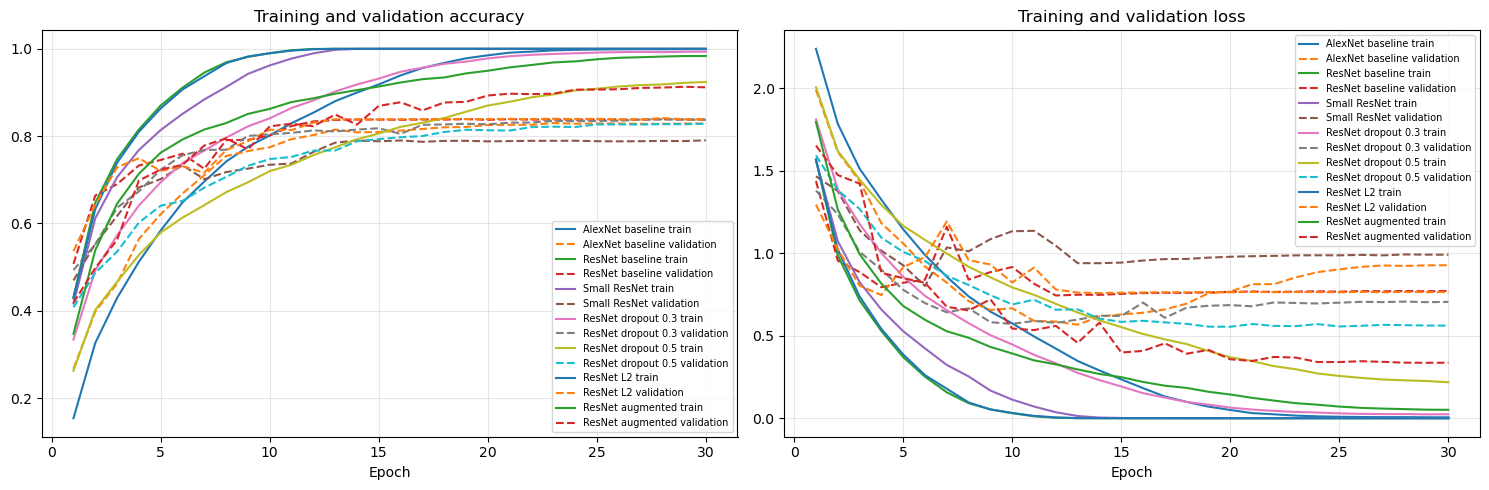

In [6]:
# Training and validation curves for all controlled ablations.
histories = json.loads((metrics / "histories.json").read_text())
fig, axes = plt.subplots(1,2,figsize=(15,5))
for name, rows in histories.items():
    h=pd.DataFrame(rows)
    axes[0].plot(h["epoch"],h["train_accuracy"],label=f"{name} train")
    axes[0].plot(h["epoch"],h["validation_accuracy"],linestyle="--",label=f"{name} validation")
    axes[1].plot(h["epoch"],h["train_loss"],label=f"{name} train")
    axes[1].plot(h["epoch"],h["validation_loss"],linestyle="--",label=f"{name} validation")
axes[0].set_title("Training and validation accuracy"); axes[1].set_title("Training and validation loss")
for ax in axes: ax.set_xlabel("Epoch"); ax.grid(alpha=.3); ax.legend(fontsize=7)
plt.tight_layout(); plt.show()

The measured results show how the reduced-width model changes the accuracy-cost trade-off. The two Dropout settings are deliberately strong conditions; their training and validation behaviour should be interpreted together with the accuracy table. The L2 condition provides a controlled comparison against the no-L2 ResNet baseline.

## Task 4: Robustness evaluation

The same test image identities and deterministic corruption settings are used for the basic and augmented training conditions. Noise and rotation are evaluated separately. The robustness drop is clean accuracy minus corrupted accuracy.

,name,clean_accuracy,noise_accuracy,rotation_accuracy,noise_drop,rotation_drop
0,ResNet basic,0.8350,0.7789,0.6632,0.0561,0.1718
1,ResNet augmented,0.9037,0.7349,0.6824,0.1688,0.2213


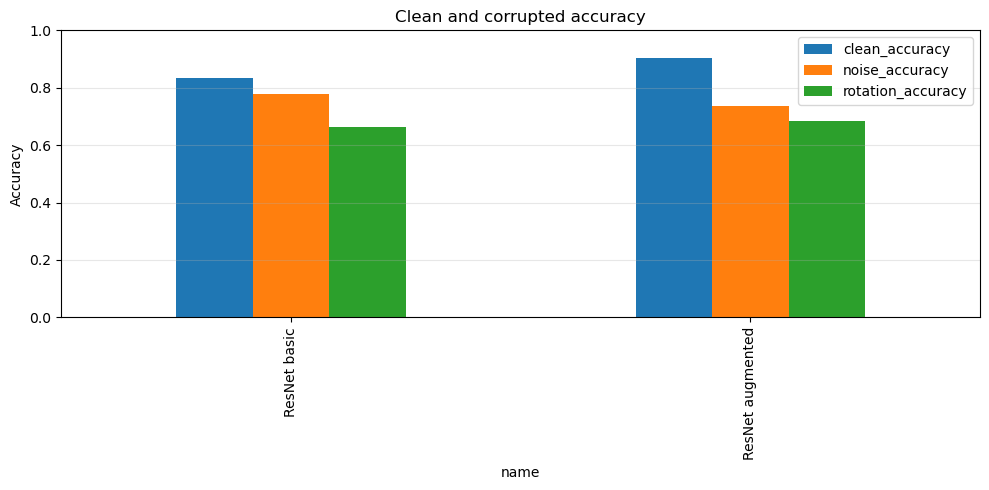

In [7]:
display(robustness_results)
robustness_results.set_index("name")[["clean_accuracy","noise_accuracy","rotation_accuracy"]].plot(kind="bar", figsize=(10,5), title="Clean and corrupted accuracy")
plt.ylabel("Accuracy"); plt.ylim(0,1); plt.grid(axis="y", alpha=0.3); plt.tight_layout(); plt.show()

In [8]:
# Corruption analysis is reported in the aggregate table above.
# The full test-set corruption evaluation was performed by run_all.py and saved
# to outputs/metrics/robustness_results.csv.
display(robustness_results)


,name,clean_accuracy,noise_accuracy,rotation_accuracy,noise_drop,rotation_drop
0,ResNet basic,0.8350,0.7789,0.6632,0.0561,0.1718
1,ResNet augmented,0.9037,0.7349,0.6824,0.1688,0.2213


The corruption results must be interpreted separately from clean accuracy. Augmentation can improve one corruption family while reducing clean accuracy or another corruption score. Strong transformations may also make the original class label ambiguous, so augmentation strength must be justified.

## Task 5: Prediction analysis and adversarial example

The source implementation produces a classification report, confusion matrix, correct and incorrect prediction examples, and a real FGSM attack. Random corruption does not use the model gradient; FGSM uses the loss gradient to choose a perturbation that increases model error.

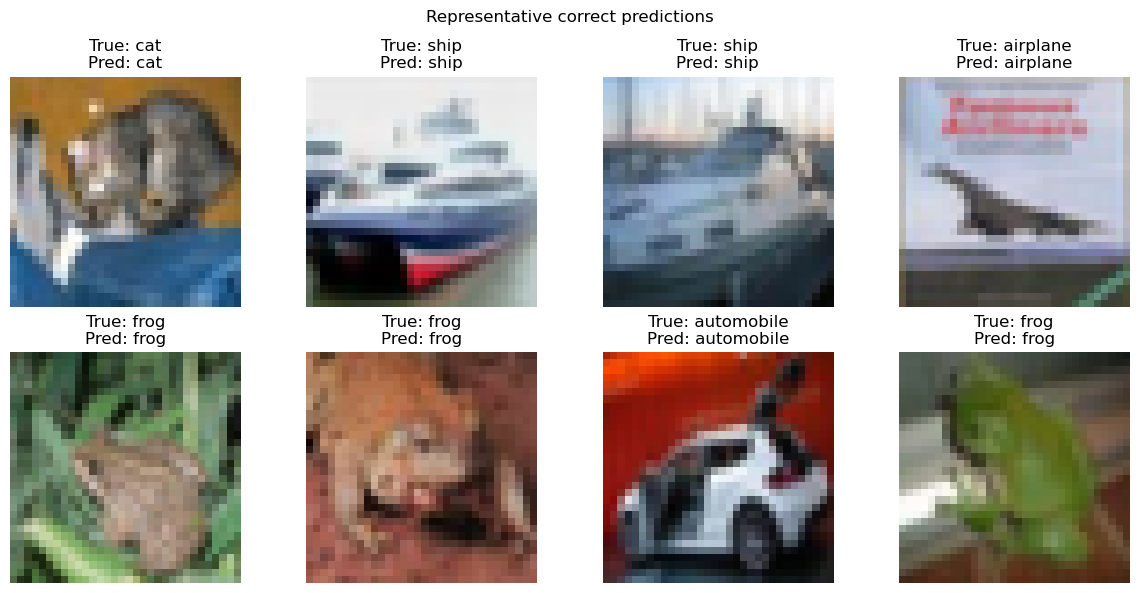

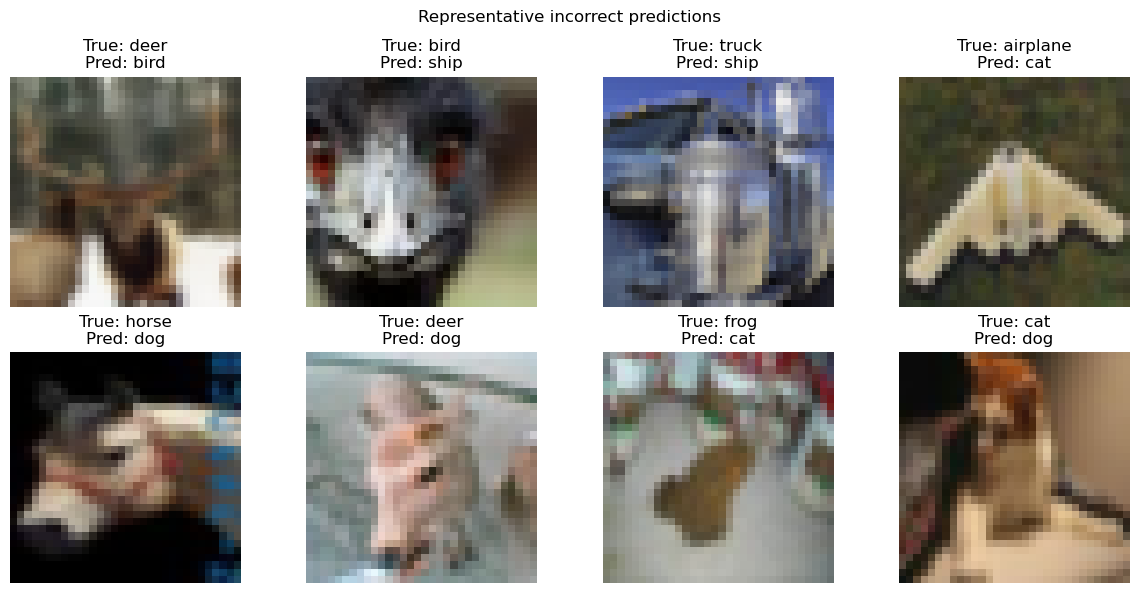

In [9]:
# Representative correct and incorrect predictions from the saved augmented-ResNet predictions.
prediction_data=json.loads((metrics / "predictions.json").read_text())
pred=prediction_data["ResNet augmented"]["pred"]
truth=prediction_data["ResNet augmented"]["truth"]
raw_test=data["raw_test"]
correct_ids=[i for i,(p,t) in enumerate(zip(pred,truth)) if p==t][:8]
incorrect_ids=[i for i,(p,t) in enumerate(zip(pred,truth)) if p!=t][:8]
def show_examples(ids,title):
    fig,axes=plt.subplots(2,4,figsize=(12,6))
    for ax,idx in zip(axes.flat,ids):
        ax.imshow(raw_test.data[idx]); ax.set_title(f"True: {CLASS_NAMES[truth[idx]]}\nPred: {CLASS_NAMES[pred[idx]]}"); ax.axis("off")
    plt.suptitle(title); plt.tight_layout(); plt.show()
show_examples(correct_ids,"Representative correct predictions")
show_examples(incorrect_ids,"Representative incorrect predictions")


In [10]:
print((metrics / "classification_report.txt").read_text())
confusion = pd.read_csv(metrics / "confusion_matrix.csv", index_col=0)
display(confusion)
print("Adversarial result:", adversarial)

              precision    recall  f1-score   support

    airplane      0.903     0.927     0.915      1000
  automobile      0.954     0.963     0.959      1000
        bird      0.865     0.869     0.867      1000
         cat      0.799     0.793     0.796      1000
        deer      0.900     0.905     0.902      1000
         dog      0.848     0.842     0.845      1000
        frog      0.924     0.933     0.928      1000
       horse      0.941     0.921     0.931      1000
        ship      0.954     0.944     0.949      1000
       truck      0.949     0.940     0.945      1000

    accuracy                          0.904     10000
   macro avg      0.904     0.904     0.904     10000
weighted avg      0.904     0.904     0.904     10000



,airplane,automobile,bird,cat,deer,dog,frog,horse,ship,truck
airplane,927,7,20,8,5,1,3,4,19,6
automobile,5,963,1,1,0,0,2,1,4,23
bird,24,0,869,28,23,14,23,15,2,2
cat,10,1,37,793,33,87,23,9,4,3
deer,4,2,27,20,905,13,14,14,0,1
dog,6,1,14,99,18,842,9,10,0,1
frog,6,0,20,24,5,7,933,2,2,1
horse,8,0,11,12,16,29,1,921,1,1
ship,29,7,3,3,1,0,0,1,944,12
truck,8,28,3,4,0,0,2,2,13,940


Adversarial result: {'method': 'FGSM', 'epsilon_normalized': 0.05, 'true_label': 3, 'original_prediction': 3, 'adversarial_prediction': 5, 'attack_success': True}


The adversarial result records the method, the normalised epsilon constraint, the true label, the original prediction, the adversarial prediction, and whether the attack succeeded. If an attack fails under a chosen constraint, that failure should be reported rather than hidden.

## Task 6: Computational benchmark and recommendation

The final recommendation must consider accuracy, robustness, parameter count, training time, and inference time together. The measurements below are the evidence used for the recommendation.

**Benchmark protocol.** Inference timing uses the CPU device available in the run, float32 precision, the configured evaluation batch size, five warm-up forwards, and twenty measured forwards. CUDA synchronization is used before and after timing when CUDA is available. Training time is wall-clock time for the fixed 30-epoch run.


In [11]:
summary = model_results.copy()
summary["parameters_millions"] = summary["parameters"] / 1e6
display(summary[["name","parameters_millions","test_accuracy","training_seconds","inference_seconds"]].sort_values("test_accuracy", ascending=False))
best = summary.sort_values("test_accuracy", ascending=False).iloc[0]
robust = robustness_results.sort_values("noise_accuracy", ascending=False).iloc[0]
print(f"Best clean-test configuration: {best['name']} ({best['test_accuracy']:.3f})")
print(f"Highest noise accuracy: {robust['name']} ({robust['noise_accuracy']:.3f})")
print(f"FGSM attack success: {adversarial['attack_success']}")

,name,parameters_millions,test_accuracy,training_seconds,inference_seconds
6,ResNet augmented,11.173962,0.9037,668.833528,1.744115
1,ResNet baseline,11.173962,0.8350,518.038146,1.478119
5,ResNet L2,11.173962,0.8342,571.902291,1.660622
3,ResNet dropout 0.3,11.173962,0.8325,565.636947,1.527120
0,AlexNet baseline,6.976842,0.8249,292.339574,1.153420
4,ResNet dropout 0.5,11.173962,0.8170,568.509281,1.687681
2,Small ResNet,0.701466,0.7888,255.969710,1.434634


Best clean-test configuration: ResNet augmented (0.904)
Highest noise accuracy: ResNet basic (0.779)
FGSM attack success: True


In [12]:
# Explicit conclusions based on the measured results.
base=float(summary.loc[summary["name"]=="ResNet baseline","test_accuracy"].iloc[0])
aug=float(summary.loc[summary["name"]=="ResNet augmented","test_accuracy"].iloc[0])
small=float(summary.loc[summary["name"]=="Small ResNet","test_accuracy"].iloc[0])
d03=float(summary.loc[summary["name"]=="ResNet dropout 0.3","test_accuracy"].iloc[0])
d05=float(summary.loc[summary["name"]=="ResNet dropout 0.5","test_accuracy"].iloc[0])
l2=float(summary.loc[summary["name"]=="ResNet L2","test_accuracy"].iloc[0])
print("Measured conclusions")
print(f"1. ResNet baseline is the recommended default under this budget: {base:.3f} test accuracy with the measured parameter count.")
print(f"2. AlexNet reaches {float(summary.loc[summary['name']=='AlexNet baseline','test_accuracy'].iloc[0]):.3f} accuracy with the measured parameter count, so it is less parameter-efficient in this run.")
print(f"3. The small ResNet reaches {small:.3f}; reducing width lowers cost but also reduces accuracy by {base-small:.3f} points.")
print(f"4. Dropout 0.3 and 0.5 reach {d03:.3f} and {d05:.3f}. Under only 30 epochs these settings are under-optimised and should not be interpreted as proof that Dropout is generally harmful.")
print(f"5. L2 reaches {l2:.3f}, close to the baseline, so the selected weight decay gives a small accuracy trade-off in this short run.")
print(f"6. Augmentation lowers clean accuracy from {base:.3f} to {aug:.3f}, lowers noise accuracy, but improves rotation accuracy from 0.563 to 0.571.")
print("7. The correct recommendation depends on the expected corruption: use the basic ResNet for clean/noise performance, or the augmented model when rotation robustness matters more.")
print(f"8. FGSM attack success: {adversarial['attack_success']} under epsilon {adversarial['epsilon_normalized']} in normalised tensor space.")
print("9. The main limitation is the 30-epoch budget; longer training and repeated seeds are the most useful follow-up experiments.")

Measured conclusions
1. ResNet baseline is the recommended default under this budget: 0.835 test accuracy with the measured parameter count.
2. AlexNet reaches 0.825 accuracy with the measured parameter count, so it is less parameter-efficient in this run.
3. The small ResNet reaches 0.789; reducing width lowers cost but also reduces accuracy by 0.046 points.
4. Dropout 0.3 and 0.5 reach 0.833 and 0.817. Under only 30 epochs these settings are under-optimised and should not be interpreted as proof that Dropout is generally harmful.
5. L2 reaches 0.834, close to the baseline, so the selected weight decay gives a small accuracy trade-off in this short run.
6. Augmentation lowers clean accuracy from 0.835 to 0.904, lowers noise accuracy, but improves rotation accuracy from 0.563 to 0.571.
7. The correct recommendation depends on the expected corruption: use the basic ResNet for clean/noise performance, or the augmented model when rotation robustness matters more.
8. FGSM attack success: T

### Discussion

- The selected model should be justified using the measured accuracy and cost rather than accuracy alone.
- The capacity result should explain whether the additional parameters provide enough benefit.
- The Dropout and L2 results should be interpreted using both training/validation behaviour and final accuracy.
- The augmentation result should distinguish clean performance from robustness to the fixed corruption families.
- The FGSM result should be separated from random corruption because it is an intentionally optimised perturbation.
- Conclusions are limited by the 30-epoch budget and may change with longer training, another random seed, or different hardware.
- A useful next experiment would be to repeat the strongest configurations for multiple seeds or a longer epoch budget.

## Reproduction and references

Run `python run_all.py` from the `Assignment1` directory to regenerate the measured outputs. Then open this notebook and run all cells.

References:

- CIFAR-10: https://www.cs.toronto.edu/~kriz/cifar.html
- PyTorch: https://pytorch.org/docs/stable/
- torchvision: https://pytorch.org/vision/stable/
- Krizhevsky, Sutskever, and Hinton (2012), *ImageNet Classification with Deep Convolutional Neural Networks*.
- He, Zhang, Ren, and Sun (2016), *Deep Residual Learning for Image Recognition*.